
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 400.  Construct portfolios from the 400 stocks in the S&P 400 mid cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp400-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AA,Alcoa,US Stocks:Materials,-82.22,-33.61,59.49,61.48,21.80,7.03,52.77,27.06,53.13,50.04,54.57,21.80,50.04,0.44
1,AAL,American Airlines Group,US Stocks:Industrials,-24.65,8.91,3.88,4.33,-2.64,-5.91,39.66,23.75,52.49,45.48,43.58,-2.64,45.48,-120.07
2,AAON,AAON,US Stocks:Industrials,-91.40,-43.57,-10.10,-7.33,7.65,11.08,52.50,32.89,72.44,57.69,50.58,7.65,57.69,0.13
3,ACI,Albertsons,US Stocks:Consumer Staples,-55.92,-48.48,-33.11,-34.27,-14.71,-7.98,31.01,11.83,24.57,19.62,21.81,-14.71,19.62,-288.61
4,ACM,AECOM,US Stocks:Industrials,0.63,-49.35,-44.21,-46.54,-6.78,2.94,59.14,41.81,30.64,28.25,26.30,-6.78,28.25,-191.53
5,ADC,Agree Realty,US Stocks:Real Estate,-2.37,-14.33,4.89,5.87,10.31,3.98,12.41,8.09,16.82,17.53,18.14,10.31,17.53,0.59
6,AEIS,Advanced Energy,US Stocks:Technology,-33.47,-33.82,77.73,86.16,33.62,27.39,80.67,41.84,58.59,43.28,39.55,33.62,43.28,0.78
7,AFG,American Financial Group,US Stocks:Financials,53.68,19.72,11.15,11.84,14.73,9.50,19.49,8.75,17.36,19.17,20.54,14.73,19.17,0.77
8,AGCO,AGCO,US Stocks:Industrials,5.28,-30.22,0.63,-0.31,-0.15,0.37,32.60,15.35,34.62,30.02,34.03,-0.15,30.02,-4.50
9,AGNC,AGNC Investment,US Stocks:Financials,31.27,5.90,27.52,27.98,20.52,6.21,13.89,6.12,18.33,25.20,30.48,20.52,25.20,0.81


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
347,TLN,Talen Energy,US Stocks:Utilities,-65.66,-36.29,-22.38,-19.59,76.34,76.34,50.62,38.32,32.58,38.14,37.21,76.34,38.14,2.00
184,IDCC,InterDigital,US Stocks:Technology,215.61,-15.59,25.41,26.55,60.06,39.00,37.20,18.04,42.54,38.83,42.51,60.06,38.83,1.55
94,CTRE,CareTrust REIT,US Stocks:Real Estate,-13.12,-3.83,17.33,19.11,30.91,18.40,20.50,16.53,18.74,19.47,24.69,30.91,19.47,1.59
66,CDE,Coeur Mining,US Stocks:Materials,43.08,-39.29,69.64,80.77,101.91,27.82,81.58,39.45,76.19,69.78,64.73,101.91,69.78,1.46
91,CRS,Carpenter Technology,US Stocks:Industrials,6.69,43.50,100.24,103.26,102.31,73.46,42.30,24.44,48.97,47.38,48.15,102.31,47.38,2.16
54,BTSG,BrightSpring Health Services,US Stocks:Healthcare,-15.54,103.70,147.10,154.07,147.10,147.10,47.25,26.16,37.54,50.63,50.63,147.10,50.63,2.91
18,AMG,Affiliated Managers Group,US Stocks:Financials,124.92,46.74,62.83,63.73,41.15,18.16,24.86,12.65,21.23,23.43,28.85,41.15,23.43,1.76
151,FTI,TechnipFMC,US Stocks:Energy,51.34,31.36,108.12,111.23,61.30,65.75,32.29,14.86,30.63,28.41,35.26,61.30,28.41,2.16
365,USFD,US Foods,US Stocks:Consumer Staples,195.01,23.29,38.18,38.61,38.12,27.20,26.71,6.78,34.66,27.81,28.81,38.12,27.81,1.37
327,SN,SharkNinja,US Stocks:Consumer Discretionary,505.83,142.23,58.97,62.68,82.95,82.95,37.37,8.29,43.52,44.02,45.33,82.95,44.02,1.88


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,TLN,IDCC,CTRE,CDE,CRS,BTSG,AMG,FTI,USFD,SN,NYT,Ranked Portfolio
Annual Returns,76.34,60.06,30.91,101.91,102.31,147.10,41.15,61.30,38.12,82.95,17.98,64.21
Std Dev,38.14,38.83,19.47,69.78,47.38,50.63,23.43,28.41,27.81,44.02,25.50,20.12
Sharpe Ratio,2.00,1.55,1.59,1.46,2.16,2.91,1.76,2.16,1.37,1.88,0.71,3.19
Weight,0.04,0.09,0.10,0.04,0.07,0.06,0.13,0.11,0.16,0.16,0.04,1.00
Worst Typical Down Year,0.06,-17.60,-8.03,-37.65,7.55,45.84,-5.71,4.48,-17.50,-5.09,-33.02,23.96
Black Swan,-38.08,-56.43,-27.50,-107.43,-39.83,-4.79,-29.14,-23.93,-45.31,-49.11,-58.52,3.84


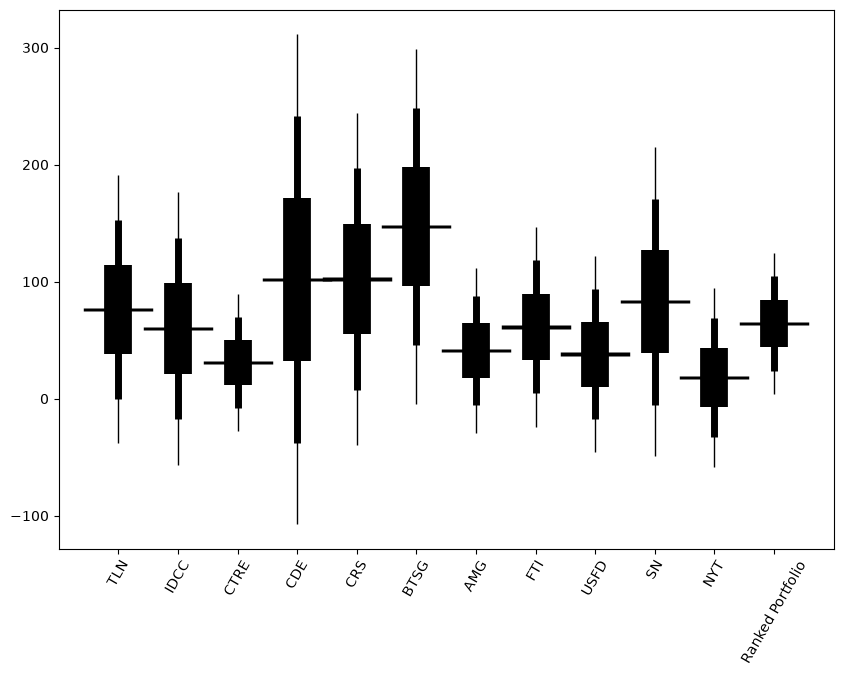

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

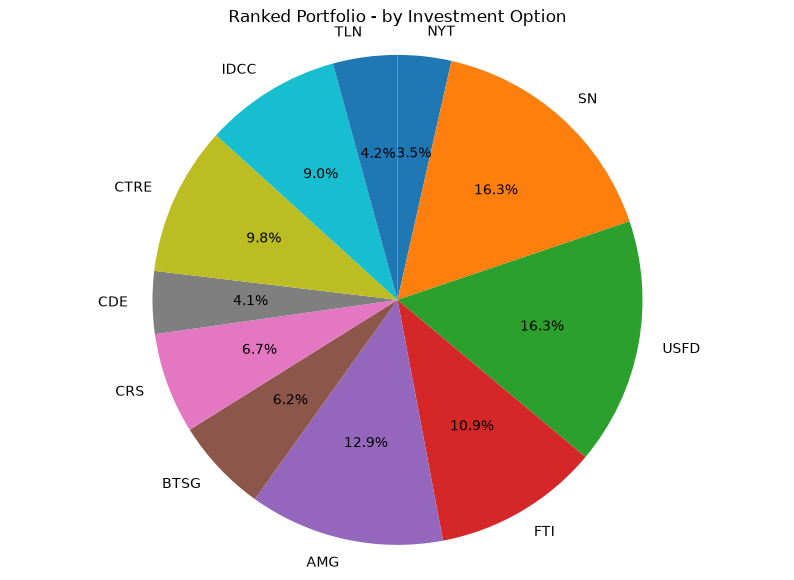

NYT    0.04
SN     0.16
USFD   0.16
FTI    0.11
AMG    0.13
BTSG   0.06
CRS    0.07
CDE    0.04
CTRE   0.10
IDCC   0.09
TLN    0.04



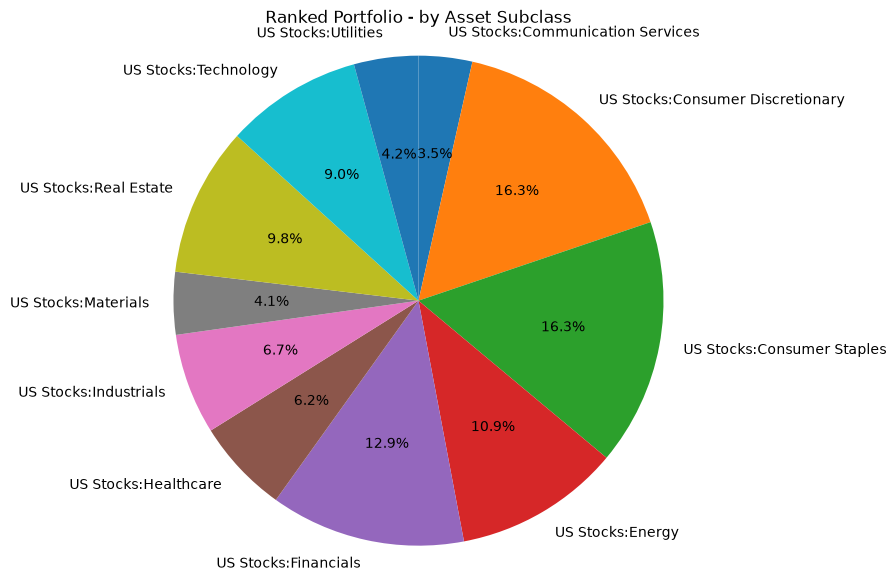

US Stocks:Communication Services   0.04
US Stocks:Consumer Discretionary   0.16
US Stocks:Consumer Staples         0.16
US Stocks:Energy                   0.11
US Stocks:Financials               0.13
US Stocks:Healthcare               0.06
US Stocks:Industrials              0.07
US Stocks:Materials                0.04
US Stocks:Real Estate              0.10
US Stocks:Technology               0.09
US Stocks:Utilities                0.04



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    TLN                            0.0425
    IDCC                           0.0902
    CTRE                           0.0984
    CDE                            0.0412
    CRS                            0.0666
    BTSG                           0.0622
    AMG                            0.1286
    FTI                            0.1095
    USFD                           0.1627
    SN                             0.1627
    NYT                            0.0353


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).